# Tutorial Class 08 Set 01

In [15]:
library(tidyverse)   # data wrangling
library(lubridate)   # dates and times
library(janitor)     # cleaning up and duplicate checks
library(vtable)      # balance table

## Prepare these Exercises before Class

### Exercise 1

### Exercise 2

In [16]:
demogs <- 
  read_csv("../../../../data/ab_test_demographics.txt")

treatment <- 
  read_csv("../../../../data/ab_test_experiment_clients.txt") |> 
  janitor::clean_names()

Rows: 70609 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): gendr
dbl (8): client_id, clnt_tenure_yr, clnt_tenure_mnth, clnt_age, num_accts, b...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 70609 Columns: 2
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): Variation
dbl (1): client_id

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [17]:
demogs <- 
  demogs |>
  inner_join(treatment, join_by(client_id))

In [18]:
# view unique values
demogs |> 
  distinct(variation)

variation
<chr>
Test
Control
NA


In [19]:
# drop missing or unusable rows
demogs <- 
  demogs |> 
  drop_na(variation)

In [20]:
demogs |> 
  select(-client_id) |> 
  st(group = 'variation')

### Exercise 3

In [21]:
weblogs_files <- c(
  '../../../../data/ab_test_web_data_pt_1.txt',
  '../../../../data/ab_test_web_data_pt_2.txt'
  )

weblog <- 
  weblogs_files |> 
  map_df(read_csv)

glimpse(weblog)

Rows: 343141 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (3): visitor_id, visit_id, process_step
dbl  (1): client_id
dttm (1): date_time

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 412264 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (3): visitor_id, visit_id, process_step
dbl  (1): client_id
dttm (1): date_time

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Rows: 755,405
Columns: 5
$ client_id    <dbl> 9988021, 9988021, 9988021, 9988021, 9988021, 9988021, 998…
$ visitor_id   <chr> "580560515_7732621733", "580560515_7732621733", "58056051…
$ visit_id     <chr> "781255054_21935453173_531117", "781255054_21935453173_53…
$ process_step <chr> "step_3", "step_2", "step_3", "step_2", "step_3", "step_2…
$ date_time    <dttm> 2017-04-17 15:27:07, 2017-04-17 15:26:51, 2017-04-17 15:…


In [22]:
weblog_clean <- 
  weblog |> 
  distinct()

In [23]:
weblog_clean <- 
  weblog_clean |> 
  inner_join(treatment, join_by(client_id)) |> 
  drop_na(variation)

## In-Class Exercises

### Exercise 4

In [24]:
completion_by_visitor <- 
  weblog_clean |>
  group_by(variation, client_id) |>
  summarise(
    completed = any(process_step == "confirm"),
    .groups = "drop"
  )

In [25]:
completion_summary <- 
  completion_by_visitor |>
  group_by(variation) |>
  summarise(
    completes = sum(completed),
    total     = n(),
    pct       = completes / total * 100,
    .groups   = "drop"
  )

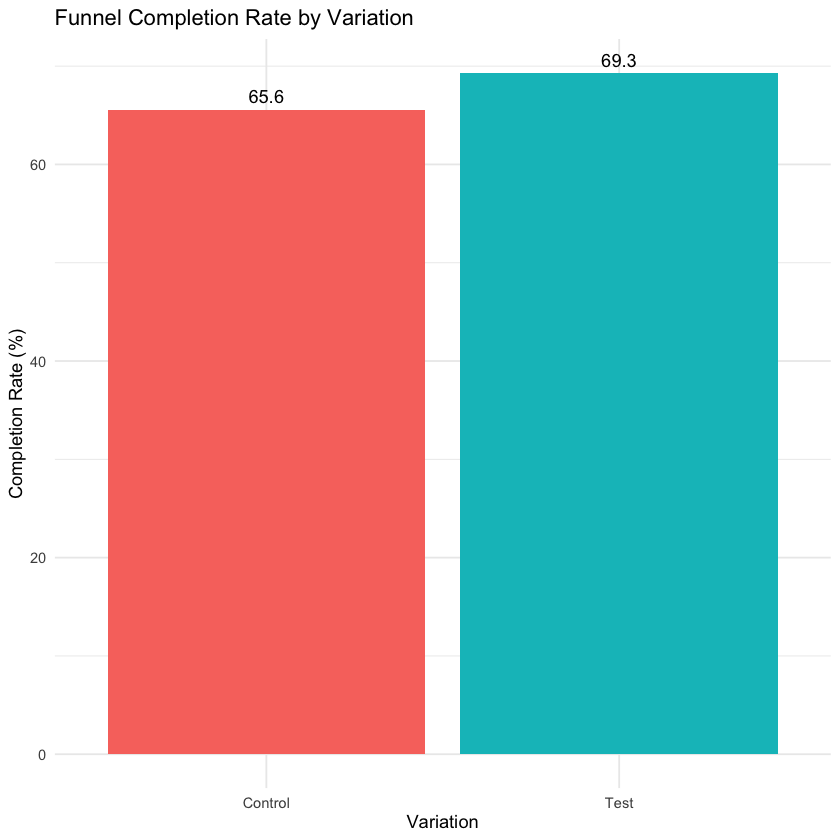

In [26]:
completion_summary |> 
  ggplot(aes(x = variation, y = pct, fill = variation)) +
  geom_col() +
  geom_text(aes(label = round(pct, 1)), vjust = -0.5) +
  labs(
    title = "Funnel Completion Rate by Variation",
    x = "Variation",
    y = "Completion Rate (%)"
  ) +
  theme_minimal() +
  theme(legend.position = "none")

In [27]:
completion_diff <- 
  completion_summary |> 
  arrange(variation) |> 
  mutate(diff_pct_points = pct - lag(pct)) |> 
  summarise(diff_pct_points = last(diff_pct_points))

completion_summary |> 
  arrange(variation) |> 
  mutate(pct_change = (pct - lag(pct)) / lag(pct) * 100)

variation,completes,total,pct,pct_change
<chr>,<int>,<int>,<dbl>,<dbl>
Control,15434,23532,65.58729,NA
Test,18687,26968,69.29324,5.650411


In [28]:
diff_rate <- completion_diff |>
    pull(diff_pct_points) / 100

control_sd <- 
    completion_by_visitor |> 
    filter(variation == "Control") |> 
    summarise(sd_rate = sd(completed)) |> 
    pull(sd_rate)

diff_sd_units <- diff_rate / control_sd
print(diff_sd_units)

[1] 0.07800477
